# Outcome prediction: what drives it, how it compares, and where it fails

Uses the two strongest tuned models from notebooks 04 and 06 (random forest and gradient boosting).
1. Grouped permutation importance: which intake information matters.
2. Per-class precision-recall (PR-AUC), as the README recommends for rare classes.
3. The at-risk (euthanasia) flag: what precision staff would get at different alert volumes.
4. Subgroups: dogs vs. cats.
5. `has_name` ablation: results with and without the owner-given-name feature, for the write-up's leakage caveat.
6. Confusion matrix and what the errors look like.

All results are on val (2022) and are associations, not causes.

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score, precision_recall_curve, ConfusionMatrixDisplay
from sklearn.pipeline import Pipeline

sys.path.append(str(Path.cwd().parent))
import utils

RESULTS_DIR = Path("results")
LABELS = utils.OUTCOME_CLASSES
train, val, test = utils.load_outcome_splits()

def tuned(est, slug):
    return utils.with_params(est, json.loads((RESULTS_DIR / f"{slug}_tuned.json").read_text())["best_params"])

MODELS = {"Random forest": tuned(RandomForestClassifier(n_jobs=-1, random_state=utils.SEED), "random_forest"),
          "Gradient boosting": tuned(HistGradientBoostingClassifier(random_state=utils.SEED), "gradient_boosting")}

def fit(est, feats=utils.FEATURES, binary=None):
    pre = utils.make_preprocessor(binary=binary) if binary is not None else utils.make_preprocessor()
    return Pipeline([("pre", pre), ("model", utils.with_params(est, {}))]).fit(train[feats], train["outcome_group"])

pipes = {k: fit(v) for k, v in MODELS.items()}
for k, p in pipes.items():
    utils.classification_metrics(val["outcome_group"], p.predict(val[utils.FEATURES]), labels=LABELS, name=k)

time_group_split: dropped 1,274 rows (0.8%) belonging to animals first seen in an earlier split


== Random forest ==  macro-F1 0.518  accuracy 0.646
                 precision    recall  f1-score   support

       Adoption       0.74      0.76      0.75      6300
       Transfer       0.55      0.36      0.44      2830
Return to Owner       0.46      0.77      0.57      1077
     Euthanasia       0.26      0.37      0.31       223

       accuracy                           0.65     10430
      macro avg       0.50      0.57      0.52     10430
   weighted avg       0.65      0.65      0.64     10430



== Gradient boosting ==  macro-F1 0.482  accuracy 0.678
                 precision    recall  f1-score   support

       Adoption       0.71      0.88      0.79      6300
       Transfer       0.62      0.32      0.42      2830
Return to Owner       0.54      0.53      0.54      1077
     Euthanasia       0.44      0.12      0.18       223

       accuracy                           0.68     10430
      macro avg       0.58      0.46      0.48     10430
   weighted avg       0.66      0.68      0.65     10430



## 1. Grouped permutation importance (drop in val macro-F1)

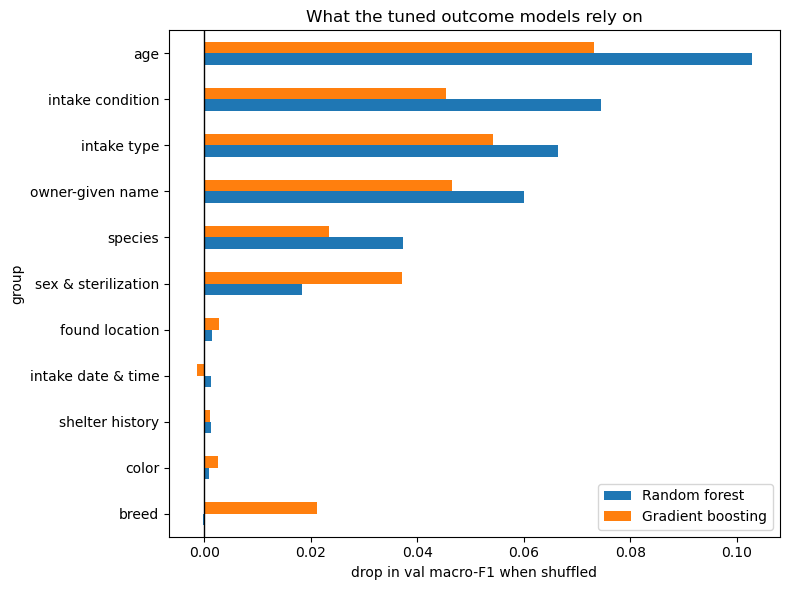

,Random forest,Gradient boosting
group,,
age,0.1029,0.0731
intake condition,0.0744,0.0455
intake type,0.0665,0.0542
owner-given name,0.0601,0.0465
species,0.0372,0.0235
sex & sterilization,0.0183,0.0371
found location,0.0014,0.0028
intake date & time,0.0013,-0.0014
shelter history,0.0012,0.0010


In [2]:
imp = {k: utils.grouped_permutation_importance(p, val[utils.FEATURES], val["outcome_group"], n_repeats=5)
       for k, p in pipes.items()}
both = pd.DataFrame({k: v.set_index("group")["importance"] for k, v in imp.items()})
both = both.sort_values("Random forest", ascending=False)
ax = both.iloc[::-1].plot(kind="barh", figsize=(8, 6))
ax.axvline(0, color="k", lw=1); ax.set_xlabel("drop in val macro-F1 when shuffled")
ax.set_title("What the tuned outcome models rely on")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_importance_grouped.png", dpi=150, bbox_inches="tight"); plt.show()
both.round(4)

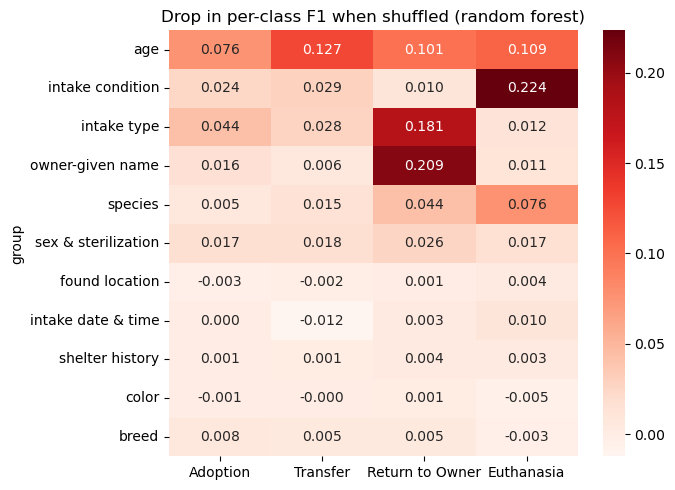

In [3]:
# Which features matter for each outcome? Permutation importance on one-vs-rest F1 per class (random forest)
from sklearn.metrics import f1_score
per_class = {}
for c in LABELS:
    metric = lambda t, p, c=c: f1_score(np.asarray(t) == c, np.asarray(p) == c, zero_division=0)
    per_class[c] = utils.grouped_permutation_importance(pipes["Random forest"], val[utils.FEATURES],
                                                        val["outcome_group"], metric=metric,
                                                        n_repeats=3).set_index("group")["importance"]
per_class = pd.DataFrame(per_class).loc[both.index]
plt.figure(figsize=(7, 5))
sns.heatmap(per_class, annot=True, fmt=".3f", cmap="Reds")
plt.title("Drop in per-class F1 when shuffled (random forest)")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "feature_importance_per_class.png", dpi=150, bbox_inches="tight"); plt.show()

## 2. Precision-recall per class (PR-AUC)

PR-AUC (average precision) summarizes how well the model ranks each class at every threshold. For a random ranking it equals the class's base rate, shown for reference.

In [4]:
proba = {k: pd.DataFrame(p.predict_proba(val[utils.FEATURES]), columns=p.classes_, index=val.index)
         for k, p in pipes.items()}
ap = pd.DataFrame({k: {c: average_precision_score(val["outcome_group"] == c, pr[c]) for c in LABELS}
                   for k, pr in proba.items()})
ap["base rate (random)"] = val["outcome_group"].value_counts(normalize=True).reindex(LABELS)
ap["lift (RF / base)"] = ap["Random forest"] / ap["base rate (random)"]
ap.round(3)

,Random forest,Gradient boosting,base rate (random),lift (RF / base)
Adoption,0.818,0.819,0.604,1.354
Transfer,0.537,0.571,0.271,1.978
Return to Owner,0.525,0.528,0.103,5.085
Euthanasia,0.240,0.224,0.021,11.208


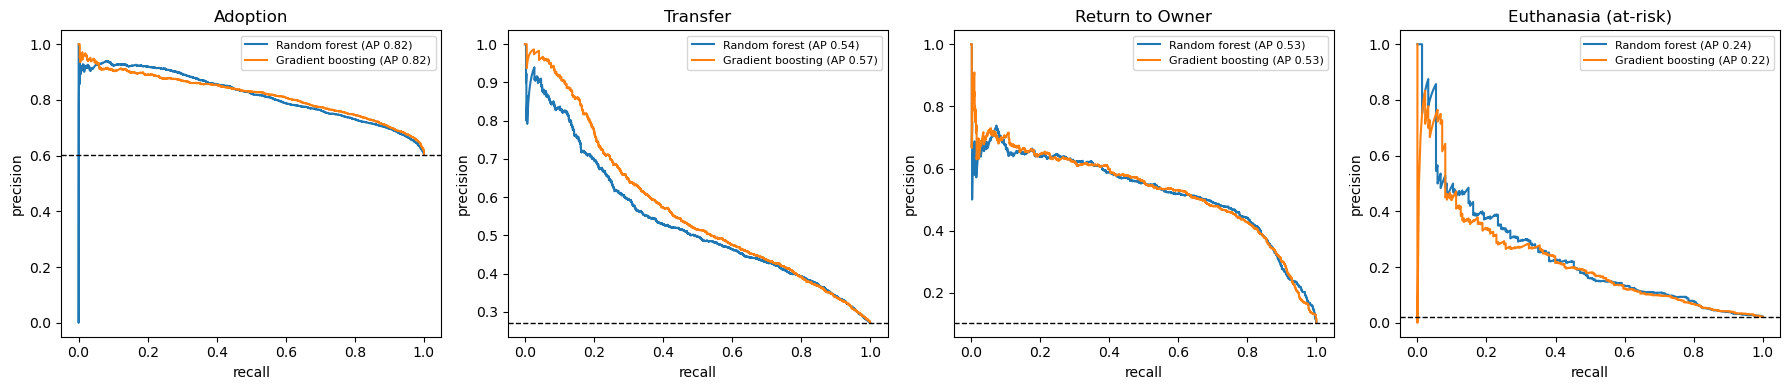

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, c in zip(axes, LABELS):
    for k, pr in proba.items():
        p, r, _ = precision_recall_curve(val["outcome_group"] == c, pr[c])
        ax.plot(r, p, label=f"{k} (AP {ap.loc[c, k]:.2f})")
    ax.axhline(ap.loc[c, "base rate (random)"], color="k", ls="--", lw=1)
    ax.set_title(c if c != "Euthanasia" else "Euthanasia (at-risk)"); ax.set_xlabel("recall"); ax.set_ylabel("precision")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig(RESULTS_DIR / "pr_curves.png", dpi=150, bbox_inches="tight"); plt.show()

## 3. The at-risk flag in practice

Imagine the dashboard flags the animals with the highest predicted at-risk (euthanasia) probability. If staff review the top N% of intakes, how many flagged animals are truly at risk (precision), and what share of all at-risk animals is caught (recall)?

In [6]:
y_risk = (val["outcome_group"] == "Euthanasia").to_numpy()
rows = []
for k, pr in proba.items():
    s = pr["Euthanasia"].to_numpy()
    order = np.argsort(-s)
    for top in [0.01, 0.02, 0.05, 0.10, 0.20]:
        n = int(len(s) * top)
        hit = y_risk[order[:n]].sum()
        rows.append({"model": k, "flag top": f"{top:.0%}", "animals flagged": n,
                     "precision": hit / n, "recall": hit / y_risk.sum()})
pd.DataFrame(rows).pivot(index="flag top", columns="model", values=["precision", "recall"]).reindex(["1%", "2%", "5%", "10%", "20%"]).round(3)

precision                          recall              
model    Gradient boosting Random forest Gradient boosting Random forest
flag top                                                                
1%                   0.375         0.394             0.175         0.184
2%                   0.274         0.308             0.256         0.287
5%                   0.196         0.196             0.457         0.457
10%                  0.128         0.131             0.596         0.614
20%                  0.081         0.084             0.762         0.785

## 4. Subgroups: dogs vs. cats

The at-risk flag works very differently by species. The cell after the table shows why: the reasons for euthanasia differ.

In [7]:
rows = []
for k, p in pipes.items():
    pred = pd.Series(p.predict(val[utils.FEATURES]), index=val.index)
    for s in ["Dog", "Cat"]:
        idx = val.index[val["animal_type"] == s]
        m = utils.classification_metrics(val.loc[idx, "outcome_group"], pred[idx], labels=LABELS, verbose=False)
        rows.append({"model": k, "species": s, "n": len(idx), "accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
                     **{f"recall_{c}": m[f"recall_{c}"] for c in LABELS}})
pd.DataFrame(rows).set_index(["model", "species"]).round(3)

n  accuracy  macro_f1  recall_Adoption  \
model             species                                              
Random forest     Dog      5916     0.600     0.421            0.749   
                  Cat      4514     0.705     0.547            0.779   
Gradient boosting Dog      5916     0.629     0.410            0.878   
                  Cat      4514     0.743     0.519            0.892   

                           recall_Transfer  recall_Return to Owner  \
model             species                                            
Random forest     Dog                0.216                   0.813   
                  Cat                0.558                   0.548   
Gradient boosting Dog                0.199                   0.561   
                  Cat                0.478                   0.401   

                           recall_Euthanasia  
model             species                     
Random forest     Dog                  0.047  
                  Cat                  0.572  
Gradient boosting Dog                  0.024  
                  Cat                  0.174

In [8]:
# Why: recorded euthanasia reason and intake condition, by species (training years)
e = train[train["outcome_group"] == "Euthanasia"]
reasons = pd.crosstab(e["outcome_subtype"].fillna("(none)"), e["animal_type"], normalize="columns")
display(reasons[reasons.max(axis=1) > 0.03].round(2))
e.groupby("animal_type")["intake_condition"].apply(lambda s: (s == "Normal").mean()).rename("share arriving in Normal condition").round(2)

animal_type,Cat,Dog
outcome_subtype,,
Aggressive,0.00,0.30
At Vet,0.05,0.03
Behavior,0.00,0.08
Medical,0.04,0.04
Rabies Risk,0.05,0.05
Suffering,0.85,0.48


animal_type
Cat    0.32
Dog    0.57
Name: share arriving in Normal condition, dtype: float64

## 5. `has_name` ablation

`has_name` is kept as a feature (team decision), but the Name field may be filled in after intake (see the EDA notebook). For the write-up, here are the results with and without it.

In [9]:
bins_wo = [c for c in utils.BINARY_FEATURES if c != "has_name"]
feats_wo = utils.NUMERIC_FEATURES + bins_wo + utils.CATEGORICAL_FEATURES
rows = []
for k, est in MODELS.items():
    for label, feats, binary, pipe in [("with has_name", utils.FEATURES, None, pipes[k]),
                                        ("without has_name", feats_wo, bins_wo, None)]:
        pipe = pipe or fit(est, feats=feats, binary=binary)
        m = utils.classification_metrics(val["outcome_group"], pipe.predict(val[feats]), labels=LABELS, verbose=False)
        rows.append({"model": k, "features": label, "accuracy": m["accuracy"], "macro_f1": m["macro_f1"],
                     **{f"recall_{c}": m[f"recall_{c}"] for c in LABELS}})
pd.DataFrame(rows).set_index(["model", "features"]).round(3)

accuracy  macro_f1  recall_Adoption  \
model             features                                                
Random forest     with has_name        0.646     0.518            0.763   
                  without has_name     0.634     0.493            0.775   
Gradient boosting with has_name        0.678     0.482            0.885   
                  without has_name     0.667     0.454            0.891   

                                    recall_Transfer  recall_Return to Owner  \
model             features                                                    
Random forest     with has_name               0.359                   0.770   
                  without has_name            0.371                   0.549   
Gradient boosting with has_name               0.316                   0.535   
                  without has_name            0.328                   0.361   

                                    recall_Euthanasia  
model             features                             
Random forest     with has_name                 0.372  
                  without has_name              0.399  
Gradient boosting with has_name                 0.117  
                  without has_name              0.126

## 6. Confusion matrix

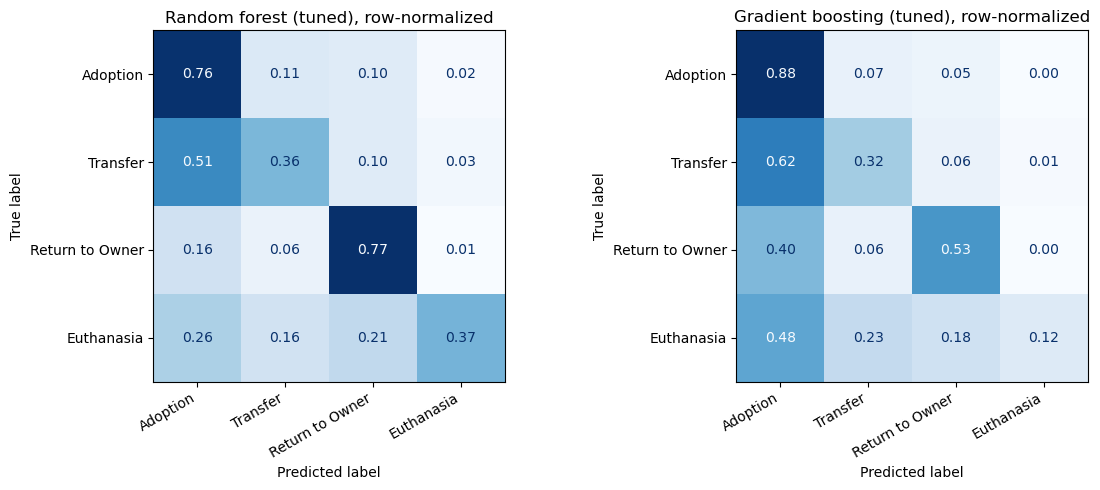

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (k, p) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_predictions(val["outcome_group"], p.predict(val[utils.FEATURES]), labels=LABELS,
                                            normalize="true", values_format=".2f", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{k} (tuned), row-normalized"); plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout(); plt.savefig(RESULTS_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight"); plt.show()

## Summary (val 2022, tuned models)

**What drives outcome predictions** (grouped permutation importance, drop in macro-F1):
- **Overall:** age (0.10) > intake condition (0.07) > intake type (0.07) > owner-given name (0.06) > species (0.04) > sex & sterilization (0.02). Breed, color, location, date and shelter history add almost nothing for the random forest.
- **Per outcome**, different information matters:
  - **At-risk (euthanasia):** intake condition (F1 drop 0.22), then age and species.
  - **Return to owner:** owner-given name (0.21) and intake type (0.18). Owned strays come with a name and get reclaimed. Caveat: `has_name` may be partly recorded after intake.
  - **Transfer:** age (0.13), driven by neonates going to foster and partners.
  - **Adoption:** spread across age, intake type and sterilization status.

**Ranking quality (PR-AUC vs. base rate):** the model ranks every class far better than chance.

| Class | Base rate | Random forest | Gradient boosting | Lift |
|---|---|---|---|---|
| Adoption | 0.60 | 0.82 | 0.82 | 1.4× |
| Transfer | 0.27 | 0.54 | 0.57 | 2× |
| Return to Owner | 0.10 | 0.53 | 0.53 | 5× |
| Euthanasia (at-risk) | 0.02 | 0.24 | 0.22 | 11× |

**The at-risk flag in practice (random forest):** flagging the top 5% of intakes catches 46% of at-risk animals at 20% precision, about 1 in 5 flagged animals. Flagging the top 10% catches 61% at 13% precision. That's useful for prioritizing vet and behavior checks, but it's a screen, not a verdict.

**Dogs vs. cats: the at-risk flag works for cats, not dogs.**
- The random forest catches **57% of at-risk cats but only 5% of at-risk dogs.**
- Cat euthanasia is mostly "Suffering" (85%), and most of those cats arrive sick or injured; only 32% come in "Normal".
- Dog euthanasia is 30% aggression + 8% behavior in training, plus court/investigation cases in val, and 57% of those dogs arrive in "Normal" condition. Behavioral risk isn't visible in the intake record.
- **Report this as a limitation,** and as a subgroup-fairness finding.

**`has_name` ablation:**
- Without the name feature, macro-F1 drops by 0.025 (random forest, 0.518 → 0.493) and 0.028 (gradient boosting, 0.482 → 0.454).
- Almost all of the loss is Return to Owner recall (random forest: 0.77 → 0.55).
- At-risk recall slightly *improves* without it (0.37 → 0.40).